# Marketplace Analytics - Exploratory Data Analysis

**Data:** Brazilian E-Commerce Public Dataset by Olist (Kaggle, CC BY-NC-SA 4.0), cleaned by
`src/cleaning/pipeline.py` (Module B).

Every chart answers one business question. The code prints the exact numbers each finding relies on,
and the charts are saved to `reports/charts/`.

**Definitions (same as the SQL analysis):**
- revenue = price + freight, on orders that are not canceled/unavailable;
- customer = `customer_unique_id`;
- trend charts use the complete months 2017-01 to 2018-08;
- delivery metrics use valid deliveries only.

**Contents**
1. Dataset overview
2. Data quality
3. Univariate analysis
4. Bivariate analysis
5. Time-series analysis
6. Product performance
7. Customer behaviour
8. Regional analysis
9. Delivery, payments and order status
10. Summary of findings

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the project root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.analysis.eda import (
    COLORS, SEQUENTIAL_BLUES, BRL_FORMATTER, PCT_FORMATTER, DELIVERY_BUCKET_ORDER,
    apply_style, add_subtitle, save_chart, load_clean, build_order_table,
    build_item_table, delivery_bucket,
)

apply_style()
pd.set_option("display.float_format", "{:,.2f}".format)

t = load_clean()
orders = build_order_table(t)       # one row per order
items = build_item_table(t)         # one row per item, revenue orders only

# Revenue orders that have items; `window` = complete months for trend charts
rev = orders[orders["is_revenue_order"] & orders["order_value"].notna()].copy()
window = rev[rev["in_analysis_window"]].copy()
valid = orders[orders["is_valid_delivery"]].copy()
print(f"orders={len(orders):,}  revenue orders={len(rev):,}  in window={len(window):,}  "
      f"valid deliveries={len(valid):,}")

orders=99,441  revenue orders=98,199  in window=97,905  valid deliveries=96,447


## 1. Dataset overview
**Question:** What data do we have, and what period does it cover?

In [2]:
overview = pd.DataFrame(
    [(name, len(df), df.shape[1]) for name, df in t.items()],
    columns=["table", "rows", "columns"],
)
display(overview)
print("Purchases from", orders["order_purchase_timestamp"].min(),
      "to", orders["order_purchase_timestamp"].max())
print(f"Unique customers: {orders['customer_unique_id'].nunique():,} | "
      f"sellers: {t['sellers'].shape[0]:,} | products: {t['products'].shape[0]:,} | "
      f"categories: {t['products']['product_category_name_english'].nunique()}")

,table,rows,columns
0,orders,99441,17
1,order_items,112650,9
2,customers,99441,5
3,products,32951,10
4,sellers,3095,4
5,payments,103883,5
6,reviews,99224,9
7,geolocation,19011,6
8,categories,74,2


Purchases from 2016-09-04 21:15:19 to 2018-10-17 17:30:18
Unique customers: 96,096 | sellers: 3,095 | products: 32,951 | categories: 74


**Finding.** 99,441 orders from 96,096 unique customers, 3,095 sellers and 32,951 products in 74 categories, purchased between 2016-09-04 and 2018-10-17. Of these, 98,199 orders count as revenue orders and 97,905 of those fall in the complete-month window used for trends.

## 2. Data quality
**Question:** Which raw fields are incomplete, and is that a data error or expected behaviour?
The full report is in `reports/data_quality_report.md`; this chart shows the columns with missing values in the raw files.

,column,missing_pct
3,reviews.review_comment_title,88.34
4,reviews.review_comment_message,58.70
2,orders.order_delivered_customer_date,2.98
6,products.product_name_lenght,1.85
5,products.product_category_name,1.85
7,products.product_description_lenght,1.85
8,products.product_photos_qty,1.85
1,orders.order_delivered_carrier_date,1.79
0,orders.order_approved_at,0.16
9,products.product_weight_g,0.01


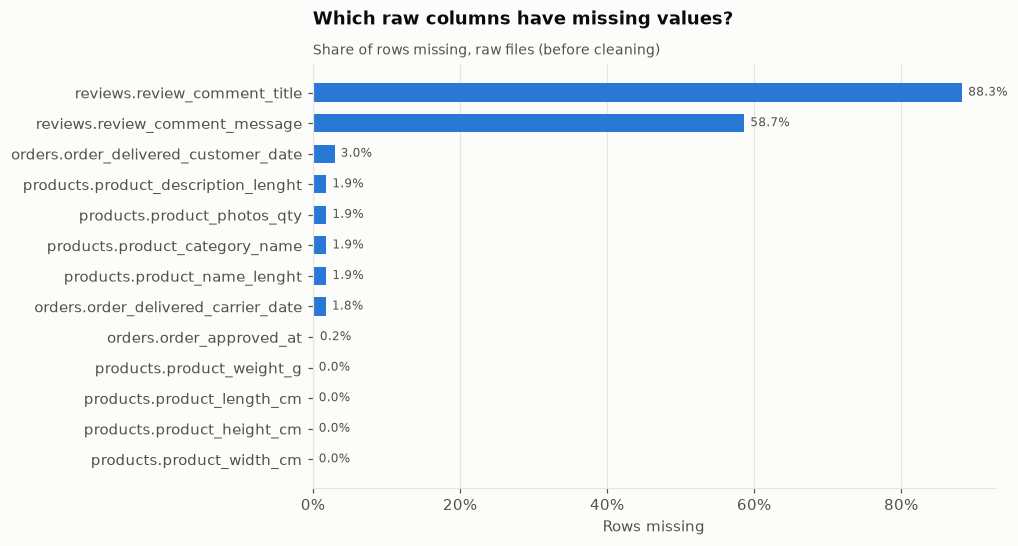

In [3]:
from src.ingestion.loader import load_raw_table

null_rows = []
for table in ["orders", "reviews", "products"]:
    raw = load_raw_table(table)
    pct = raw.isna().mean().mul(100)
    for col, value in pct[pct > 0].items():
        null_rows.append((f"{table}.{col}", value))
nulls = pd.DataFrame(null_rows, columns=["column", "missing_pct"]).sort_values("missing_pct")
display(nulls.sort_values("missing_pct", ascending=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(nulls["column"], nulls["missing_pct"], color=COLORS["primary"], height=0.6)
ax.xaxis.set_major_formatter(PCT_FORMATTER)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for y, v in enumerate(nulls["missing_pct"]):
    ax.text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=8, color=COLORS["text_muted"])
ax.set_title("Which raw columns have missing values?")
add_subtitle(ax, "Share of rows missing, raw files (before cleaning)")
ax.set_xlabel("Rows missing")
save_chart(fig, "02_missing_values"); plt.show()

**Finding.** Missing values are mostly **expected behaviour, not errors**. Review comments are optional (88.3% have no title, 58.7% no message). Delivery dates are missing where the order was never delivered (3.0%). The only true gaps are the 1.85% of products with no category or description, which cleaning labels `unknown`. No key column has missing values.

## 3. Univariate analysis
### 3.1 How much does a typical order cost?

median R$105.28 | mean R$160.24 | 90th pct R$307.14 | max R$13,664.08
orders under R$100: 47.5% | over R$500: 4.3%


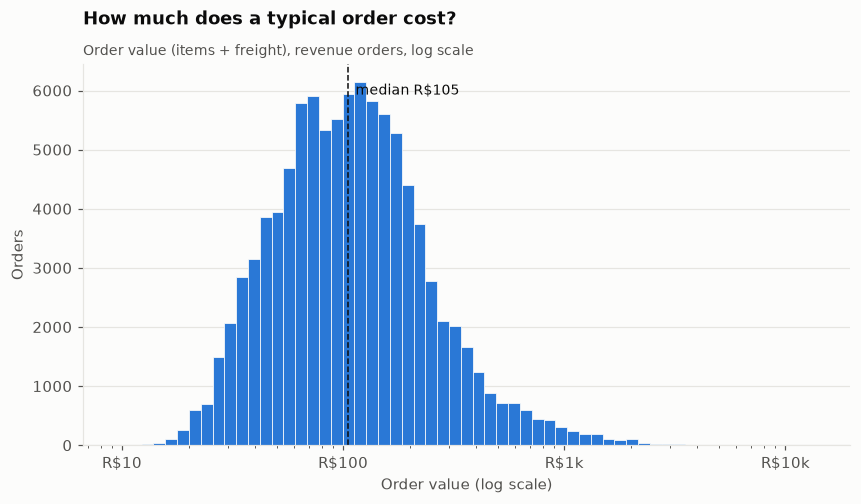

In [4]:
values = rev["order_value"]
print(f"median R${values.median():,.2f} | mean R${values.mean():,.2f} | "
      f"90th pct R${values.quantile(0.9):,.2f} | max R${values.max():,.2f}")
print(f"orders under R$100: {(values < 100).mean():.1%} | over R$500: {(values > 500).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 60)
ax.hist(values, bins=bins, color=COLORS["primary"], edgecolor=COLORS["surface"], linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(BRL_FORMATTER)
ax.axvline(values.median(), color=COLORS["text"], linewidth=1, linestyle="--")
ax.text(values.median() * 1.08, ax.get_ylim()[1] * 0.92, f"median R${values.median():.0f}", fontsize=9)
ax.set_title("How much does a typical order cost?")
add_subtitle(ax, "Order value (items + freight), revenue orders, log scale")
ax.set_xlabel("Order value (log scale)"); ax.set_ylabel("Orders")
save_chart(fig, "03_order_value_distribution"); plt.show()

**Finding.** Order values are **heavily right-skewed**: the median order is R$105.28 but the mean is R$160.24, pulled up by a long tail of up to R$13,664. 47.5% of orders are under R$100 and only 4.3% exceed R$500. This is why the median is the better description of a typical order, and why dashboards should not rely on the mean alone.

### 3.2 How satisfied are customers?

{1: 11.52, 2: 3.17, 3: 8.24, 4: 19.29, 5: 57.77} | mean score 4.09 | reviewed orders 98,673


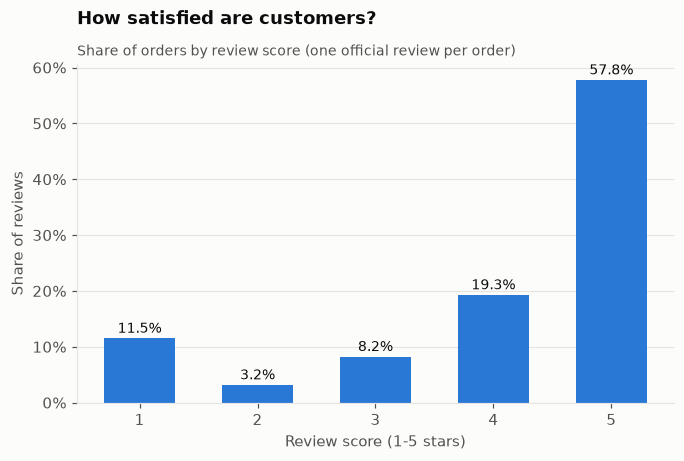

In [5]:
scores = orders["review_score"].dropna().astype(int)
dist = scores.value_counts(normalize=True).sort_index().mul(100)
print(dist.round(2).to_dict(), f"| mean score {scores.mean():.2f} | reviewed orders {len(scores):,}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(dist.index.astype(str), dist.values, color=COLORS["primary"], width=0.6)
for x, v in zip(dist.index.astype(str), dist.values):
    ax.text(x, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PCT_FORMATTER)
ax.set_title("How satisfied are customers?")
add_subtitle(ax, "Share of orders by review score (one official review per order)")
ax.set_xlabel("Review score (1-5 stars)"); ax.set_ylabel("Share of reviews")
save_chart(fig, "03_review_score_distribution"); plt.show()

**Finding.** Satisfaction is **polarised**: 57.8% of reviews are 5 stars, but the next-largest group is 1 star (11.5%), well ahead of 2 stars (3.2%) and 3 stars (8.2%). The mean of 4.09 hides a meaningful unhappy minority. Section 4.1 shows what drives it.

### 3.3 How long does delivery take, compared with the promise?

actual: median 10.2 d, mean 12.6 d, 95th pct 29.3 d | promised: median 23.2 d
deliveries over 30 days: 4.7% (chart is cut at 60 days: 306 orders beyond)


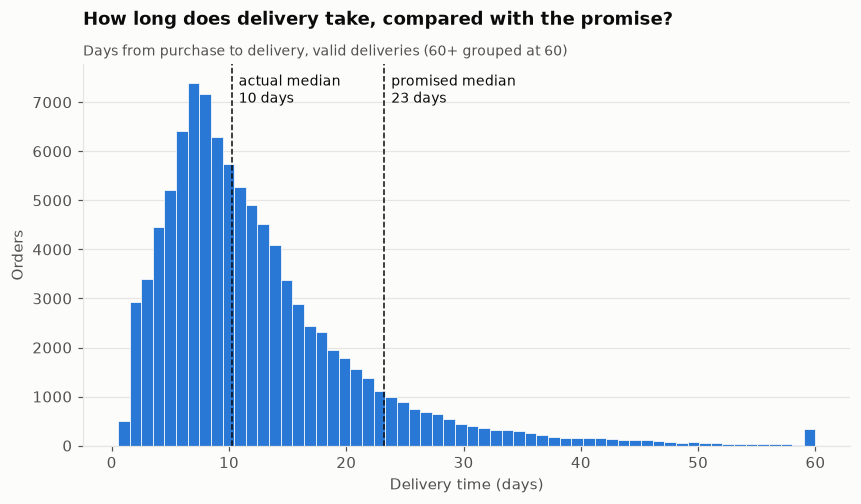

In [6]:
d = valid["delivery_days"]; promised = valid["estimated_delivery_days"]
print(f"actual: median {d.median():.1f} d, mean {d.mean():.1f} d, 95th pct {d.quantile(0.95):.1f} d | "
      f"promised: median {promised.median():.1f} d")
print(f"deliveries over 30 days: {(d > 30).mean():.1%} (chart is cut at 60 days: {(d > 60).sum():,} orders beyond)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(d.clip(upper=60), bins=60, color=COLORS["primary"], edgecolor=COLORS["surface"], linewidth=0.5)
for value, label in [(d.median(), "actual median"), (promised.median(), "promised median")]:
    ax.axvline(value, color=COLORS["text"], linewidth=1, linestyle="--")
    ax.text(value + 0.6, ax.get_ylim()[1] * 0.9, f"{label}\n{value:.0f} days", fontsize=9)
ax.set_title("How long does delivery take, compared with the promise?")
add_subtitle(ax, "Days from purchase to delivery, valid deliveries (60+ grouped at 60)")
ax.set_xlabel("Delivery time (days)"); ax.set_ylabel("Orders")
save_chart(fig, "03_delivery_time_distribution"); plt.show()

**Finding.** The median delivery takes **10 days, against a median promise of 23 days**. Olist pads its estimates heavily, which is why only a minority of orders are late even though some deliveries are slow (95th percentile 29.3 days; 4.7% take over 30 days).

## 4. Bivariate analysis
### 4.1 Does late delivery hurt review scores?

,reviews,avg_score,pct_1_2_star
delivery_outcome,,,
7+ days early,75721,4.31,8.99
1-6 days early,12419,4.18,10.59
on promised day,1280,4.03,12.42
1-3 days late,1852,3.29,32.13
4-7 days late,1748,2.10,67.68
8+ days late,2781,1.70,79.29
not delivered / no valid date,2872,1.76,77.75


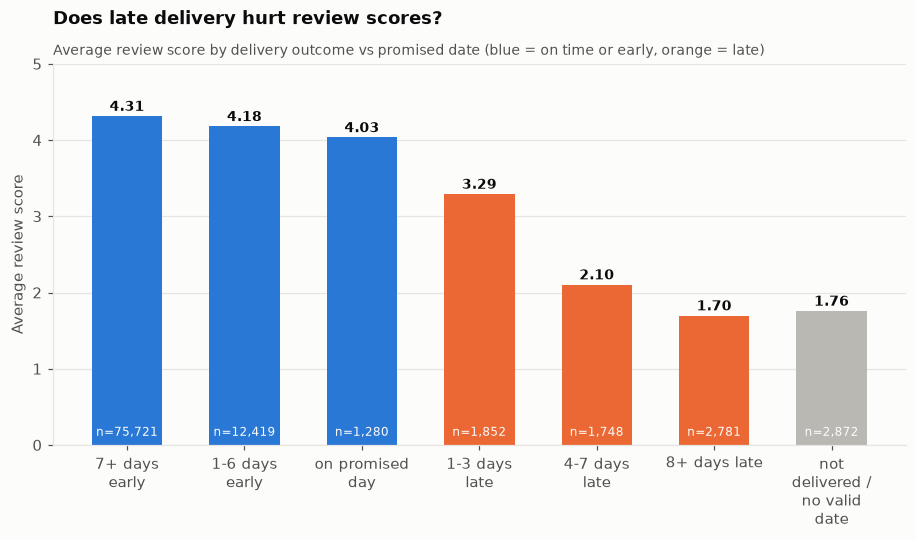

In [7]:
reviewed = orders[orders["review_score"].notna()].copy()
reviewed["delivery_outcome"] = [
    delivery_bucket(delay, ok) for delay, ok in zip(reviewed["delivery_delay_days"], reviewed["is_valid_delivery"])
]
by_bucket = (reviewed.groupby("delivery_outcome")
             .agg(reviews=("review_score", "size"), avg_score=("review_score", "mean"),
                  pct_1_2_star=("review_score", lambda s: (s <= 2).mean() * 100))
             .reindex(DELIVERY_BUCKET_ORDER))
display(by_bucket)

colors = [COLORS["primary"]] * 3 + [COLORS["secondary"]] * 3 + [COLORS["neutral"]]
fig, ax = plt.subplots(figsize=(10, 4.5))
import textwrap
labels = [textwrap.fill(b, 12) for b in by_bucket.index]   # wrap long bucket names
ax.bar(labels, by_bucket["avg_score"], color=colors, width=0.6)
for x, (v, n) in enumerate(zip(by_bucket["avg_score"], by_bucket["reviews"])):
    ax.text(x, v + 0.07, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")
    ax.text(x, 0.12, f"n={n:,}", ha="center", fontsize=8, color=COLORS["surface"])
ax.set_ylim(0, 5)
ax.set_title("Does late delivery hurt review scores?")
add_subtitle(ax, "Average review score by delivery outcome vs promised date (blue = on time or early, orange = late)")
ax.set_ylabel("Average review score")
save_chart(fig, "04_review_vs_delivery"); plt.show()

**Finding.** This is the **strongest relationship in the dataset**. Orders that arrive early average 4.18-4.31 stars. Once an order is late, the score falls steeply: 3.29 at 1-3 days late, 2.10 at 4-7 days and 1.70 at 8+ days. 79.3% of reviews for orders 8+ days late are 1-2 stars, against 9.0% for orders a week early. Orders never delivered score 1.76. Delivery reliability is a direct lever on customer satisfaction.

### 4.2 Does product weight drive freight cost?

excluded 383 free-shipping items from this chart
items=111,692 | Pearson r=0.61 | Spearman rho=0.45


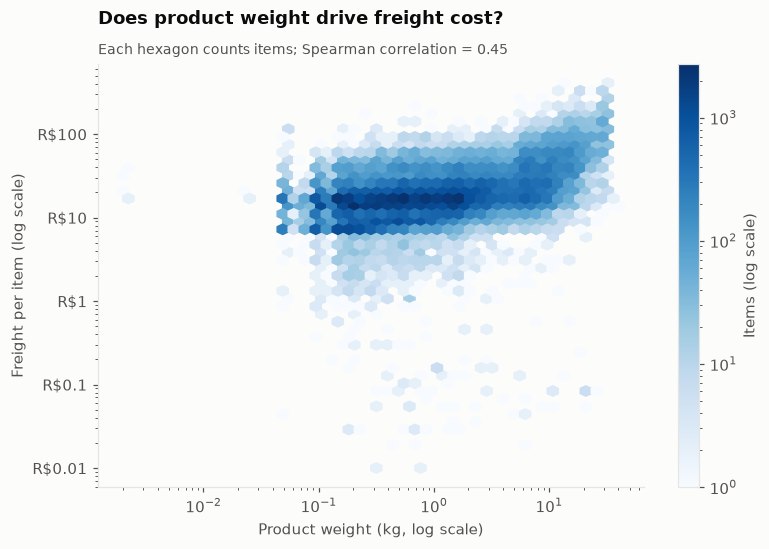

In [8]:
w_all = items.dropna(subset=["product_weight_g"])
# Free-shipping items (freight = 0) cannot sit on a log axis; they are excluded here only.
w = w_all[w_all["freight_value"] > 0]
print(f"excluded {len(w_all) - len(w):,} free-shipping items from this chart")
pearson = w["product_weight_g"].corr(w["freight_value"])
# Spearman = Pearson correlation of the ranks (robust to the long tail; no scipy needed)
spearman = w["product_weight_g"].rank().corr(w["freight_value"].rank())
print(f"items={len(w):,} | Pearson r={pearson:.2f} | Spearman rho={spearman:.2f}")

fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(w["product_weight_g"] / 1000, w["freight_value"], gridsize=45, bins="log",
               cmap=SEQUENTIAL_BLUES, mincnt=1, xscale="log", yscale="log")
fig.colorbar(hb, ax=ax, label="Items (log scale)")
ax.grid(False)
ax.yaxis.set_major_formatter(BRL_FORMATTER)
ax.set_title("Does product weight drive freight cost?")
add_subtitle(ax, f"Each hexagon counts items; Spearman correlation = {spearman:.2f}")
ax.set_xlabel("Product weight (kg, log scale)"); ax.set_ylabel("Freight per item (log scale)")
save_chart(fig, "04_weight_vs_freight"); plt.show()

**Finding.** Heavier products cost more to ship (Spearman rho = 0.45, Pearson r = 0.61 across 111,692 items with paid freight; 383 free-shipping items excluded). The wide vertical spread at any weight shows that **distance (region) also drives freight**, which section 8.1 confirms.

### 4.3 Do customers use installments for bigger purchases?

,size,median,mean
installment_group,,,
1,23728,71.63,100.81
2-3,22409,111.43,135.30
4-6,15974,128.14,182.15
7-10,11665,206.49,333.71
11+,336,214.17,360.12


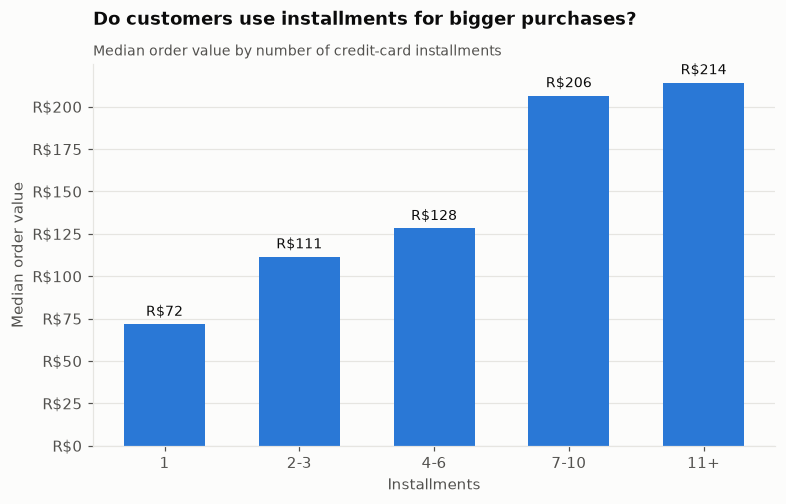

In [9]:
card = rev[rev["payment_type"] == "credit_card"].copy()
card["installment_group"] = pd.cut(card["payment_installments"], [0, 1, 3, 6, 10, 24],
                                   labels=["1", "2-3", "4-6", "7-10", "11+"])
inst = card.groupby("installment_group", observed=True)["order_value"].agg(["size", "median", "mean"])
display(inst)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(inst.index.astype(str), inst["median"], color=COLORS["primary"], width=0.6)
for x, (m, n) in enumerate(zip(inst["median"], inst["size"])):
    ax.text(x, m + 5, f"R${m:,.0f}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(BRL_FORMATTER)
ax.set_title("Do customers use installments for bigger purchases?")
add_subtitle(ax, "Median order value by number of credit-card installments")
ax.set_xlabel("Installments"); ax.set_ylabel("Median order value")
save_chart(fig, "04_installments_vs_order_value"); plt.show()

**Finding.** Installments are used for bigger purchases: the median card order is R$72 when paid at once, R$111 in 2-3 installments, R$128 in 4-6 and R$206-214 in 7+. Installment availability likely enables higher-value purchases, which matters for pricing and payment strategy.

## 5. Time-series analysis
### 5.1 How did revenue and order volume grow?

,revenue,orders
purchase_year_month,,
2018-06-01,"1,020,381.90",6145
2018-07-01,"1,039,783.58",6233
2018-08-01,"996,973.51",6421


Jan-Aug revenue 2017 R$3,574,992.04 -> 2018 R$8,593,137.50 (+140.4%)
Best month: 2017-11 R$1,172,191.68


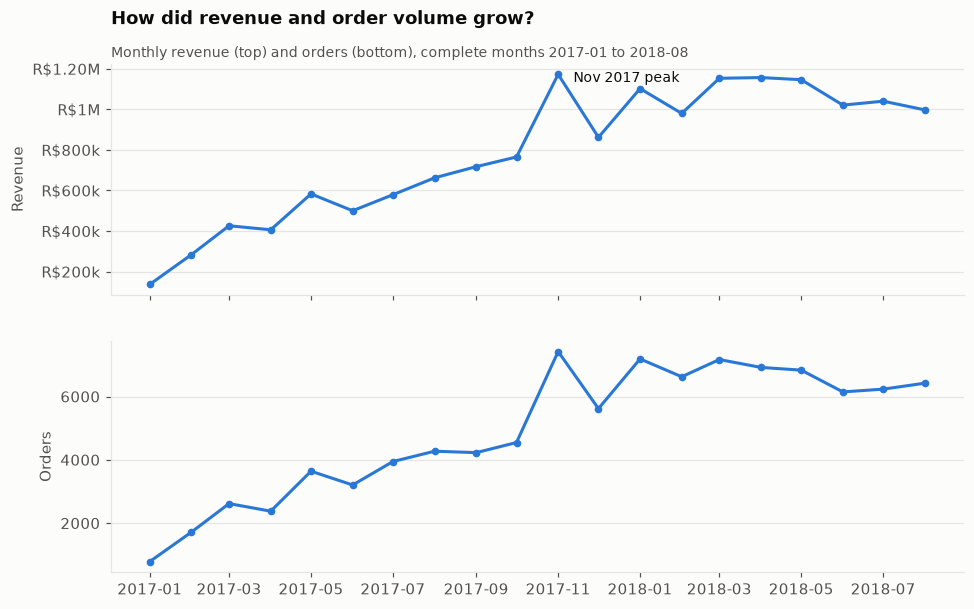

In [10]:
monthly = (window.groupby("purchase_year_month")
           .agg(revenue=("order_value", "sum"), orders=("order_id", "nunique")))
monthly.index = pd.PeriodIndex(monthly.index, freq="M").to_timestamp()
display(monthly.tail(3))
jan_aug = {y: monthly.loc[f"{y}-01":f"{y}-08", "revenue"].sum() for y in (2017, 2018)}
print(f"Jan-Aug revenue 2017 R${jan_aug[2017]:,.2f} -> 2018 R${jan_aug[2018]:,.2f} "
      f"({jan_aug[2018] / jan_aug[2017] - 1:+.1%})")
print("Best month:", monthly["revenue"].idxmax().strftime("%Y-%m"), f"R${monthly['revenue'].max():,.2f}")

# Two measures with different scales -> two aligned panels, never a dual axis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(monthly.index, monthly["revenue"], color=COLORS["primary"], marker="o", markersize=4)
ax1.yaxis.set_major_formatter(BRL_FORMATTER)
ax1.set_title("How did revenue and order volume grow?")
add_subtitle(ax1, "Monthly revenue (top) and orders (bottom), complete months 2017-01 to 2018-08")
ax1.set_ylabel("Revenue")
ax2.plot(monthly.index, monthly["orders"], color=COLORS["primary"], marker="o", markersize=4)
ax2.set_ylabel("Orders")
peak = monthly["revenue"].idxmax()
ax1.annotate("Nov 2017 peak", (peak, monthly.loc[peak, "revenue"]), xytext=(10, -5),
             textcoords="offset points", fontsize=9)
save_chart(fig, "05_monthly_revenue_orders"); plt.show()

**Finding.** Revenue grew strongly through 2017, peaking in **November 2017 at R$1.17M** (the Black Friday month). Jan-Aug 2018 revenue (R$8.59M) was **140.4% higher** than Jan-Aug 2017 (R$3.57M). During 2018, however, monthly revenue **plateaued at about R$1.0-1.16M**: growth slowed after the early-2018 jump.

### 5.2 Which days had unusual order spikes?

Top days: {'2017-11-24 (Fri)': 1166, '2017-11-25 (Sat)': 498, '2017-11-27 (Mon)': 400}
median daily orders in window: 150


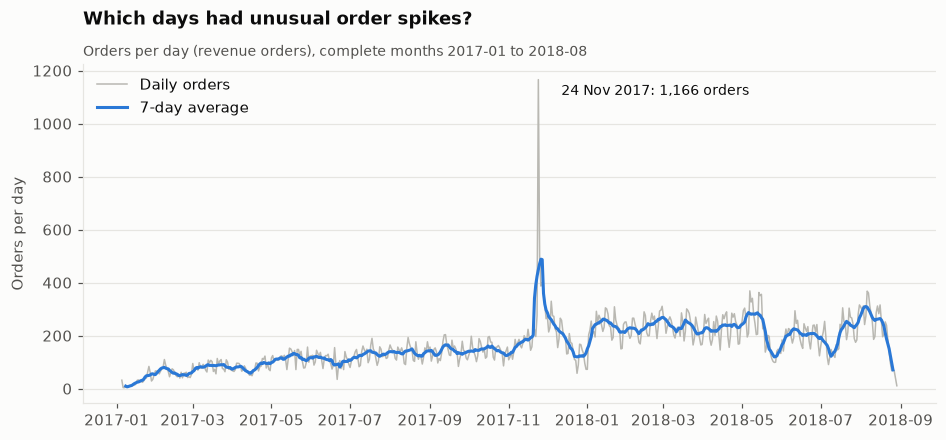

In [11]:
daily = window.groupby(window["order_purchase_timestamp"].dt.normalize())["order_id"].nunique()
top_days = daily.nlargest(3)
print("Top days:", {d.strftime("%Y-%m-%d (%a)"): int(n) for d, n in top_days.items()})
print(f"median daily orders in window: {daily.median():.0f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily.values, color=COLORS["neutral"], linewidth=1, label="Daily orders")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color=COLORS["primary"], label="7-day average")
peak_day = top_days.index[0]
ax.annotate(f"{peak_day:%d %b %Y}: {top_days.iloc[0]:,} orders", (peak_day, top_days.iloc[0]),
            xytext=(15, -10), textcoords="offset points", fontsize=9)
ax.legend(loc="upper left")
ax.set_title("Which days had unusual order spikes?")
add_subtitle(ax, "Orders per day (revenue orders), complete months 2017-01 to 2018-08")
ax.set_ylabel("Orders per day")
save_chart(fig, "05_daily_orders"); plt.show()

**Finding.** Black Friday stands out clearly: **24 Nov 2017 (Friday) had 1,166 orders**, about 7.8x the median day of 150 orders, and the following Saturday and Monday were also elevated (498 and 400). Peak events create sudden load, which section 9.1 links to delivery problems.

### 5.3 When during the week do customers buy?

Orders by weekday: {'Monday': 15978, 'Tuesday': 15758, 'Wednesday': 15350, 'Thursday': 14571, 'Friday': 13948, 'Saturday': 10763, 'Sunday': 11831}
busiest hour 16:00 | 10:00-21:59 share 75.7% | weekend share 23.0%


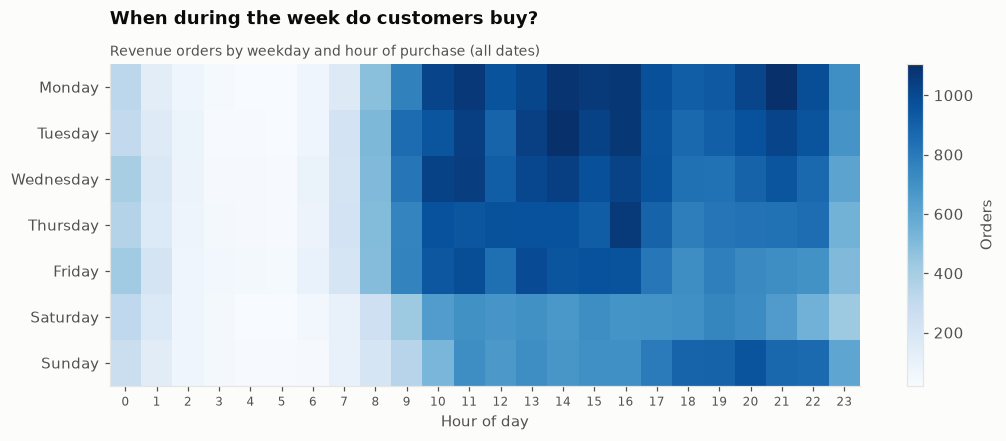

In [12]:
ts = rev["order_purchase_timestamp"]
heat = (pd.crosstab(ts.dt.day_name(), ts.dt.hour)
        .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))
by_day = heat.sum(axis=1); by_hour = heat.sum(axis=0)
print("Orders by weekday:", by_day.to_dict())
print(f"busiest hour {by_hour.idxmax()}:00 | 10:00-21:59 share {by_hour.loc[10:21].sum() / by_hour.sum():.1%} | "
      f"weekend share {by_day[['Saturday', 'Sunday']].sum() / by_day.sum():.1%}")

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, aspect="auto", cmap=SEQUENTIAL_BLUES)
ax.set_xticks(range(24)); ax.set_xticklabels(range(24), fontsize=8)
ax.set_yticks(range(7)); ax.set_yticklabels(heat.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Orders")
ax.set_title("When during the week do customers buy?")
add_subtitle(ax, "Revenue orders by weekday and hour of purchase (all dates)")
ax.set_xlabel("Hour of day")
save_chart(fig, "05_weekday_hour_heatmap"); plt.show()

**Finding.** Customers buy mostly on **weekdays during the day**. Monday and Tuesday are the busiest days, the weekend is only 23.0% of orders, the peak hour is 16:00, and 75.7% of orders are placed between 10:00 and 21:59. Marketing pushes and customer-service staffing should follow this pattern.

## 6. Product performance
### 6.1 Which categories generate the most revenue?

,revenue,units,orders,share_pct
category,,,,
health_beauty,"1,255,695.13",9634,8800,9.31
watches_gifts,"1,198,185.21",5970,5604,8.88
bed_bath_table,"1,035,964.06",11097,9399,7.68
sports_leisure,"979,740.92",8590,7673,7.26
computers_accessories,"904,322.02",7781,6654,6.70
furniture_decor,"727,465.05",8298,6425,5.39
housewares,"626,825.80",6915,5847,4.65
cool_stuff,"620,770.49",3779,3616,4.60
auto,"586,585.73",4204,3872,4.35


top 10 categories = 62.4% of product revenue, out of 74 categories


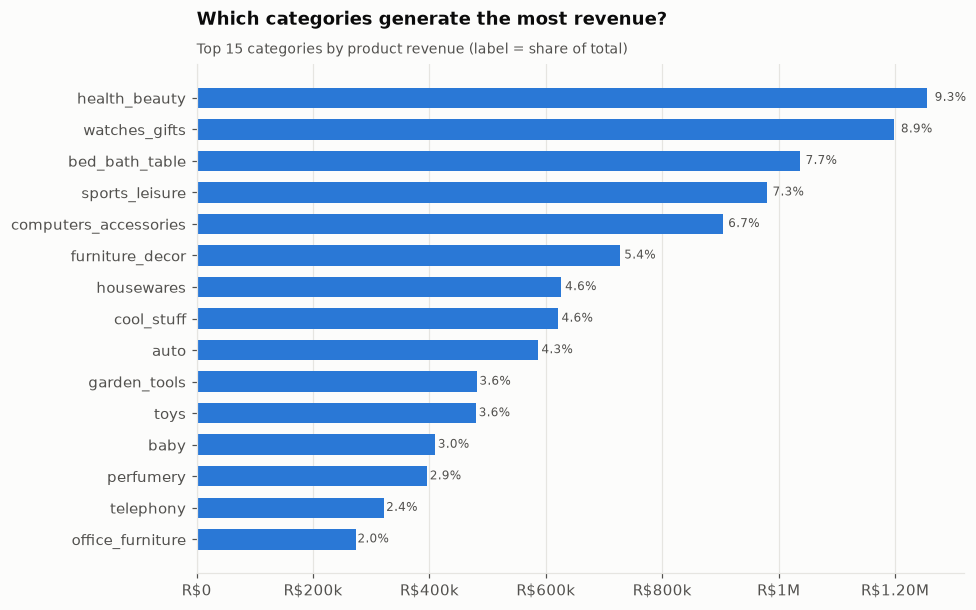

In [13]:
cat = (items.groupby("category")
       .agg(revenue=("price", "sum"), units=("order_item_id", "size"), orders=("order_id", "nunique"))
       .sort_values("revenue", ascending=False))
cat["share_pct"] = cat["revenue"] / cat["revenue"].sum() * 100
top15 = cat.head(15)
display(top15.head(10))
print(f"top 10 categories = {cat['share_pct'].head(10).sum():.1f}% of product revenue, "
      f"out of {len(cat)} categories")

fig, ax = plt.subplots(figsize=(9, 6))
plot = top15.iloc[::-1]
ax.barh(plot.index, plot["revenue"], color=COLORS["primary"], height=0.65)
for y, (v, s) in enumerate(zip(plot["revenue"], plot["share_pct"])):
    ax.text(v * 1.01, y, f"{s:.1f}%", va="center", fontsize=8, color=COLORS["text_muted"])
ax.xaxis.set_major_formatter(BRL_FORMATTER)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Which categories generate the most revenue?")
add_subtitle(ax, "Top 15 categories by product revenue (label = share of total)")
save_chart(fig, "06_top_categories"); plt.show()

**Finding.** Revenue is spread across many categories but led by **health_beauty (9.3%), watches_gifts (8.9%) and bed_bath_table (7.7%)**. The top 10 of 74 categories make up 62.4% of product revenue. watches_gifts earns its rank with far fewer units than bed_bath_table (5,970 vs 11,097), so its items are much more expensive.

### 6.2 Do the biggest categories also satisfy customers?

categories with >= 100 orders: 52 | revenue vs review correlation r=0.00
Lowest-rated: {'office_furniture': 3.62, 'fashion_male_clothing': 3.73, 'audio': 3.84}
Highest-rated: {'books_general_interest': 4.5, 'books_technical': 4.4, 'food_drink': 4.4}


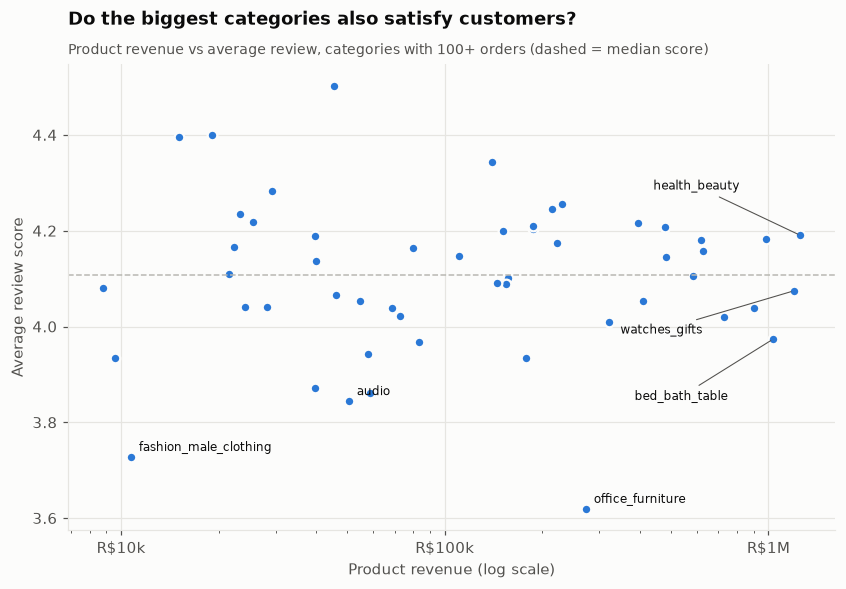

In [14]:
order_scores = orders[["order_id", "review_score"]].dropna()
cat_reviews = (items[["order_id", "category"]].drop_duplicates()
               .merge(order_scores, on="order_id").groupby("category")["review_score"].mean())
cat2 = cat.join(cat_reviews.rename("avg_review")).query("orders >= 100")
print(f"categories with >= 100 orders: {len(cat2)} | "
      f"revenue vs review correlation r={cat2['revenue'].corr(cat2['avg_review']):.2f}")
print("Lowest-rated:", cat2.nsmallest(3, "avg_review")["avg_review"].round(2).to_dict())
print("Highest-rated:", cat2.nlargest(3, "avg_review")["avg_review"].round(2).to_dict())

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(cat2["revenue"], cat2["avg_review"], s=40, color=COLORS["primary"],
           edgecolor=COLORS["surface"], linewidth=1.5)
# Label only the top 3 by revenue (offset down-left to avoid crowding) and the 3 lowest-rated.
for offset, name in zip([(-40, 30), (-60, -28), (-30, -40)], cat2.nlargest(3, "revenue").index):
    ax.annotate(name, (cat2.loc[name, "revenue"], cat2.loc[name, "avg_review"]),
                xytext=offset, textcoords="offset points", fontsize=8, ha="right",
                arrowprops={"arrowstyle": "-", "color": COLORS["text_muted"], "linewidth": 0.7})
for name in cat2.nsmallest(3, "avg_review").index:
    ax.annotate(name, (cat2.loc[name, "revenue"], cat2.loc[name, "avg_review"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.axhline(cat2["avg_review"].median(), color=COLORS["neutral"], linewidth=1, linestyle="--")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(BRL_FORMATTER)
ax.grid(axis="x")
ax.set_title("Do the biggest categories also satisfy customers?")
add_subtitle(ax, "Product revenue vs average review, categories with 100+ orders (dashed = median score)")
ax.set_xlabel("Product revenue (log scale)"); ax.set_ylabel("Average review score")
save_chart(fig, "06_category_revenue_vs_review"); plt.show()

**Finding.** Across the 52 categories with 100+ orders, revenue and satisfaction are **uncorrelated (r = 0.00)**: selling more does not mean satisfying more. office_furniture (3.62), fashion_male_clothing (3.73) and audio (3.84) are the lowest-rated categories and are candidates for quality or seller reviews. Books and food_drink score highest (4.4-4.5).

### 6.3 How concentrated is revenue among sellers?

sellers with sales: 3,053 | top 10% -> 67.5% | top 20% -> 82.6% | 80% of revenue comes from 540 sellers (17.7%)


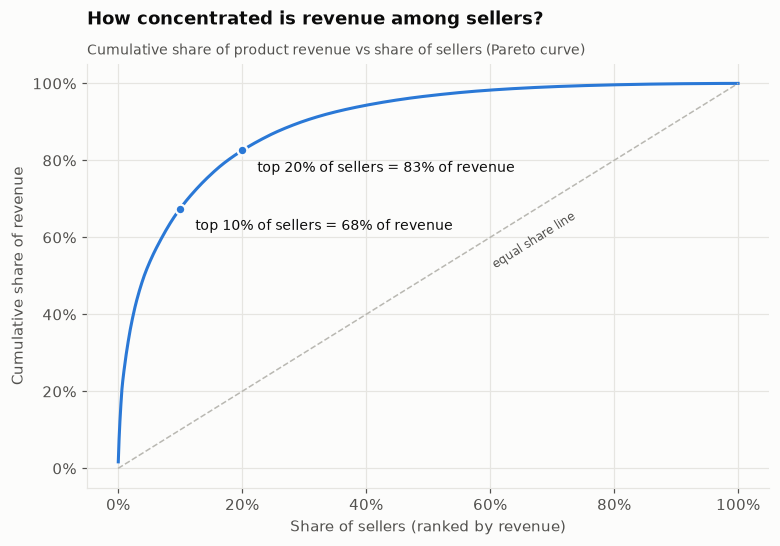

In [15]:
seller_rev = items.groupby("seller_id")["price"].sum().sort_values(ascending=False)
cum_share = seller_rev.cumsum() / seller_rev.sum() * 100
seller_pct = np.arange(1, len(seller_rev) + 1) / len(seller_rev) * 100
def share_of_top(pct): return cum_share.iloc[int(np.ceil(len(seller_rev) * pct / 100)) - 1]
sellers_for_80 = (cum_share < 80).sum() + 1
print(f"sellers with sales: {len(seller_rev):,} | top 10% -> {share_of_top(10):.1f}% | "
      f"top 20% -> {share_of_top(20):.1f}% | 80% of revenue comes from {sellers_for_80:,} sellers "
      f"({sellers_for_80 / len(seller_rev):.1%})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(seller_pct, cum_share.values, color=COLORS["primary"])
ax.plot([0, 100], [0, 100], color=COLORS["neutral"], linewidth=1, linestyle="--")
ax.text(60, 52, "equal share line", fontsize=8, color=COLORS["text_muted"], rotation=32)
for pct in (10, 20):
    ax.scatter(pct, share_of_top(pct), color=COLORS["primary"], s=40, zorder=3,
               edgecolor=COLORS["surface"], linewidth=1.5)
    ax.annotate(f"top {pct}% of sellers = {share_of_top(pct):.0f}% of revenue", (pct, share_of_top(pct)),
                xytext=(10, -14), textcoords="offset points", fontsize=9)
ax.xaxis.set_major_formatter(PCT_FORMATTER); ax.yaxis.set_major_formatter(PCT_FORMATTER)
ax.grid(axis="x")
ax.set_title("How concentrated is revenue among sellers?")
add_subtitle(ax, "Cumulative share of product revenue vs share of sellers (Pareto curve)")
ax.set_xlabel("Share of sellers (ranked by revenue)"); ax.set_ylabel("Cumulative share of revenue")
save_chart(fig, "06_seller_pareto"); plt.show()

**Finding.** Revenue is **highly concentrated**: the top 10% of sellers earn 67.5% of product revenue and the top 20% earn 82.6%. 80% of revenue comes from 540 of 3,053 sellers (17.7%), a classic Pareto pattern. Losing a few top sellers would be a material risk, so they warrant account management.

## 7. Customer behaviour
### 7.1 How often do customers come back?

{'1': 92096, '2': 2651, '3': 188, '4+': 48} | repeat customers 3.04%


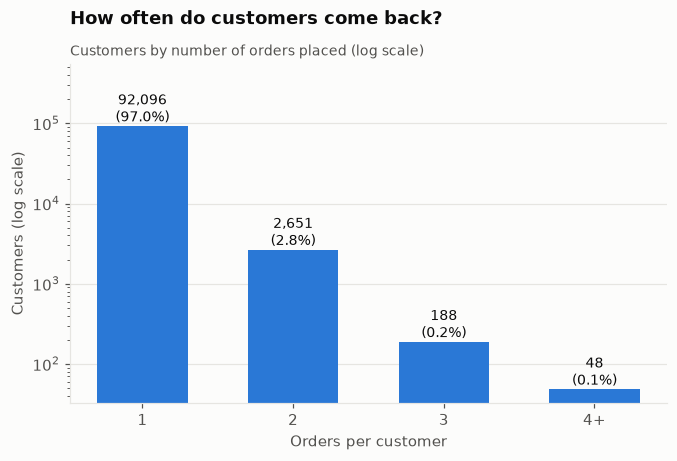

In [16]:
per_customer = rev.groupby("customer_unique_id").agg(orders=("order_id", "nunique"),
                                                      revenue=("order_value", "sum"))
freq = per_customer["orders"].clip(upper=4).value_counts().sort_index()
freq.index = ["1", "2", "3", "4+"]
print(freq.to_dict(), f"| repeat customers {(per_customer['orders'] >= 2).mean():.2%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(freq.index, freq.values, color=COLORS["primary"], width=0.6)
ax.set_yscale("log")
for x, v in zip(freq.index, freq.values):
    ax.text(x, v * 1.15, f"{v:,}\n({v / freq.sum():.1%})", ha="center", fontsize=9)
ax.set_ylim(top=freq.max() * 6)
ax.set_title("How often do customers come back?")
add_subtitle(ax, "Customers by number of orders placed (log scale)")
ax.set_xlabel("Orders per customer"); ax.set_ylabel("Customers (log scale)")
save_chart(fig, "07_purchase_frequency"); plt.show()

**Finding.** **97.0% of customers ordered only once**. Only 2,887 customers (3.04%) came back, and just 48 ordered 4+ times. Retention is the biggest untapped opportunity in this business.

### 7.2 When repeat customers return, how long do they wait?

repeat customers: 2,887 | same day (<1 day): 31.0% | within 30 days: 50.8% | median gap 28 days | median gap excluding same-day 77 days


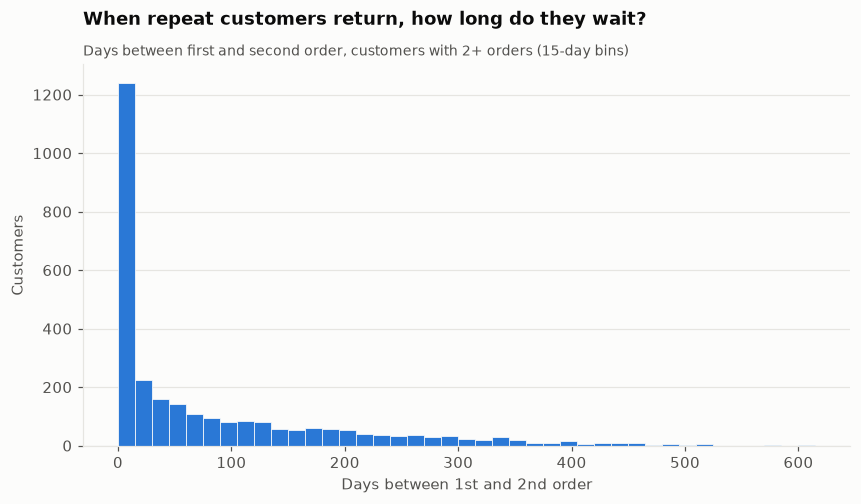

In [17]:
ordered = rev.sort_values("order_purchase_timestamp")
ordered["order_number"] = ordered.groupby("customer_unique_id").cumcount() + 1
first_two = ordered[ordered["order_number"] <= 2].pivot(
    index="customer_unique_id", columns="order_number", values="order_purchase_timestamp").dropna()
gap_days = (first_two[2] - first_two[1]).dt.total_seconds() / 86400
print(f"repeat customers: {len(gap_days):,} | same day (<1 day): {(gap_days < 1).mean():.1%} | "
      f"within 30 days: {(gap_days <= 30).mean():.1%} | median gap {gap_days.median():.0f} days | "
      f"median gap excluding same-day {gap_days[gap_days >= 1].median():.0f} days")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(gap_days, bins=np.arange(0, gap_days.max() + 15, 15), color=COLORS["primary"],
        edgecolor=COLORS["surface"], linewidth=0.5)
ax.set_title("When repeat customers return, how long do they wait?")
add_subtitle(ax, "Days between first and second order, customers with 2+ orders (15-day bins)")
ax.set_xlabel("Days between 1st and 2nd order"); ax.set_ylabel("Customers")
save_chart(fig, "07_days_to_second_order"); plt.show()

**Finding.** Among repeat customers, **31.0% placed their second order on the same day** as the first, which looks like split baskets rather than true loyalty. Excluding those, the median wait is 77 days. Genuine repeat purchasing is therefore even rarer than 3%.

## 8. Regional analysis
### 8.1 Which states generate the most revenue?

,revenue,orders,freight,product_value,share_pct,freight_pct_of_order
customer_state,,,,,,
SP,"5,878,132.06",41125,"714,264.84","5,163,867.22",37.36,12.15
RJ,"2,115,667.56",12697,"304,044.14","1,811,623.42",13.45,14.37
MG,"1,843,074.43",11496,"269,566.23","1,573,508.20",11.71,14.63
RS,"877,290.59",5415,"134,730.81","742,559.78",5.58,15.36
PR,"794,196.61",4982,"117,313.55","676,883.06",5.05,14.77


top 3 states (SP, RJ, MG) = 62.5% of revenue
freight as % of order value - lowest: {'SP': 12.2, 'MS': 14.1} highest: {'RR': 22.2, 'MA': 20.8}


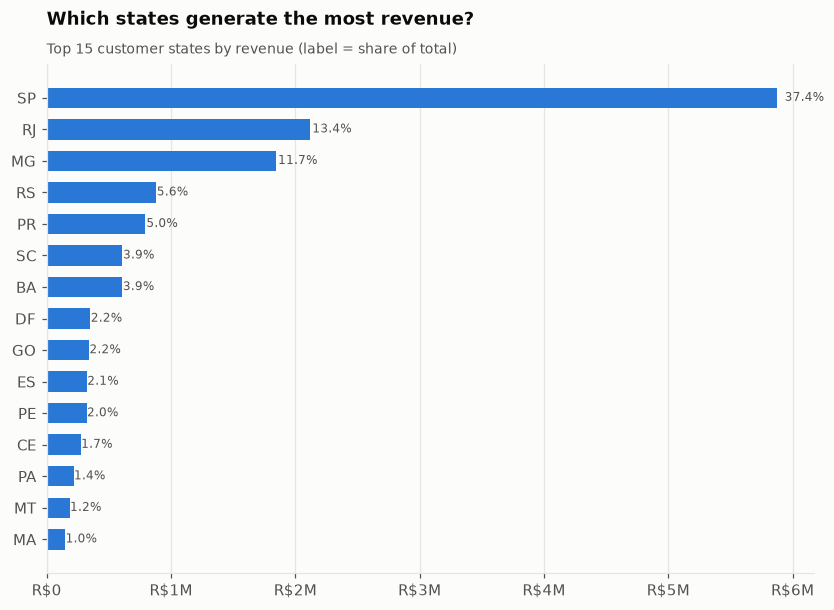

In [18]:
state = (rev.groupby("customer_state")
         .agg(revenue=("order_value", "sum"), orders=("order_id", "nunique"),
              freight=("freight", "sum"), product_value=("product_value", "sum"))
         .sort_values("revenue", ascending=False))
state["share_pct"] = state["revenue"] / state["revenue"].sum() * 100
state["freight_pct_of_order"] = state["freight"] / state["revenue"] * 100
display(state.head(5))
print(f"top 3 states (SP, RJ, MG) = {state['share_pct'].head(3).sum():.1f}% of revenue")
print("freight as % of order value - lowest:", state["freight_pct_of_order"].nsmallest(2).round(1).to_dict(),
      "highest:", state["freight_pct_of_order"].nlargest(2).round(1).to_dict())

fig, ax = plt.subplots(figsize=(9, 6))
plot = state.head(15).iloc[::-1]
ax.barh(plot.index, plot["revenue"], color=COLORS["primary"], height=0.65)
for y, (v, s) in enumerate(zip(plot["revenue"], plot["share_pct"])):
    ax.text(v * 1.01, y, f"{s:.1f}%", va="center", fontsize=8, color=COLORS["text_muted"])
ax.xaxis.set_major_formatter(BRL_FORMATTER)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Which states generate the most revenue?")
add_subtitle(ax, "Top 15 customer states by revenue (label = share of total)")
save_chart(fig, "08_revenue_by_state"); plt.show()

**Finding.** **SP alone generates 37.4% of revenue**, and SP + RJ + MG together 62.5%. Freight is also cheapest for SP customers (12.2% of order value) and most expensive in remote states such as RR (22.2%) and MA (20.8%).

### 8.2 Where is delivery slow and unreliable?

slowest: {'RR': 29.4, 'AP': 27.2, 'AM': 26.4}
most late: {'AL': 21.4, 'MA': 17.4, 'SE': 15.2}
correlation avg days vs late %: r=0.32


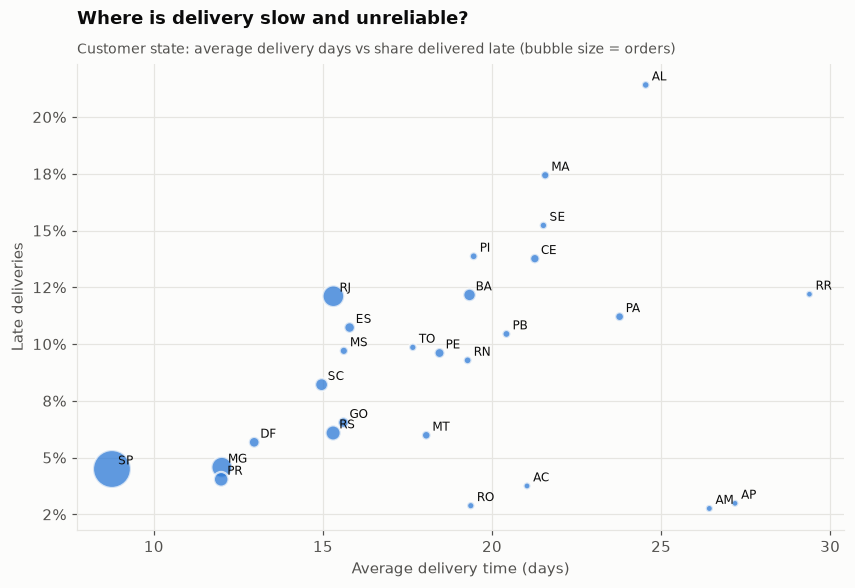

In [19]:
state_delivery = (valid.groupby("customer_state")
                  .agg(orders=("order_id", "size"), avg_days=("delivery_days", "mean"),
                       late_pct=("is_late", lambda s: s.astype(float).mean() * 100)))
print("slowest:", state_delivery["avg_days"].nlargest(3).round(1).to_dict())
print("most late:", state_delivery["late_pct"].nlargest(3).round(1).to_dict())
print(f"correlation avg days vs late %: r={state_delivery['avg_days'].corr(state_delivery['late_pct']):.2f}")

fig, ax = plt.subplots(figsize=(9, 5.5))
sizes = 20 + 600 * state_delivery["orders"] / state_delivery["orders"].max()
ax.scatter(state_delivery["avg_days"], state_delivery["late_pct"], s=sizes, color=COLORS["primary"],
           alpha=0.75, edgecolor=COLORS["surface"], linewidth=1.5)
for st, row in state_delivery.iterrows():
    ax.annotate(st, (row["avg_days"], row["late_pct"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.yaxis.set_major_formatter(PCT_FORMATTER)
ax.grid(axis="x")
ax.set_title("Where is delivery slow and unreliable?")
add_subtitle(ax, "Customer state: average delivery days vs share delivered late (bubble size = orders)")
ax.set_xlabel("Average delivery time (days)"); ax.set_ylabel("Late deliveries")
save_chart(fig, "08_state_delivery_performance"); plt.show()

**Finding.** Delivery performance varies hugely by state. **RR, AP and AM take 26-29 days** on average, yet their late rates are low, because their promised dates are longer. **AL (21.4%), MA (17.4%) and SE (15.2%) are late most often**. The weak correlation (r = 0.32) shows that slow and late are different problems: some states need faster logistics, others more accurate promises. SP is fast and reliable.

### 8.3 Where are the customers?

customers placed on the map: 99,162 of 99,441 (99.72%)


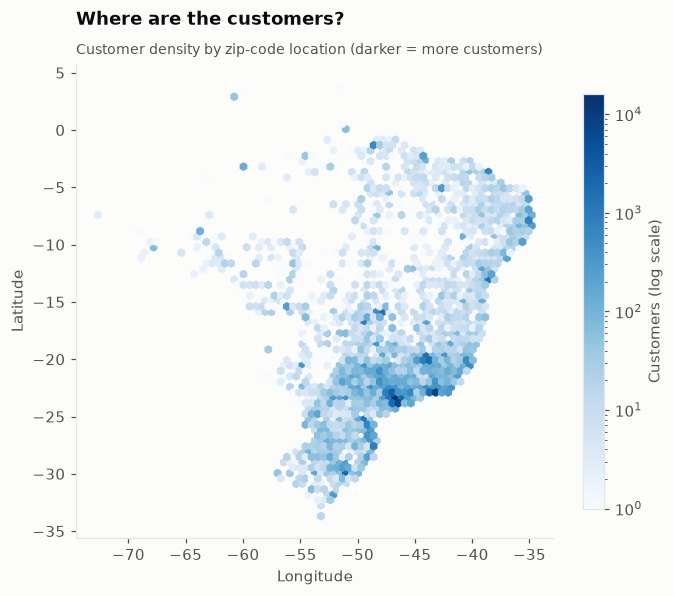

In [20]:
geo = t["geolocation"].rename(columns={"geolocation_zip_code_prefix": "zip"})
cust_geo = t["customers"].merge(geo, left_on="customer_zip_code_prefix", right_on="zip", how="inner")
print(f"customers placed on the map: {len(cust_geo):,} of {len(t['customers']):,} "
      f"({len(cust_geo) / len(t['customers']):.2%})")

fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(cust_geo["geolocation_lng"], cust_geo["geolocation_lat"], gridsize=70, bins="log",
               cmap=SEQUENTIAL_BLUES, mincnt=1)
fig.colorbar(hb, ax=ax, label="Customers (log scale)", shrink=0.7)
ax.set_aspect("equal"); ax.grid(False)
ax.set_title("Where are the customers?")
add_subtitle(ax, "Customer density by zip-code location (darker = more customers)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
save_chart(fig, "08_customer_map"); plt.show()

**Finding.** 99.72% of customers can be placed on the map. Customer density follows Brazil's population: concentrated along the south-east coast (Sao Paulo and Rio de Janeiro), with sparse coverage in the North and Centre-West interior.

## 9. Delivery, payments and order status
### 9.1 Is delivery reliability getting better or worse?

worst months (late %): {'2018-03': 18.96, '2018-02': 14.13, '2017-11': 12.4}
best months (late %): {'2018-06': 1.16, '2017-07': 2.8, '2017-08': 2.91}


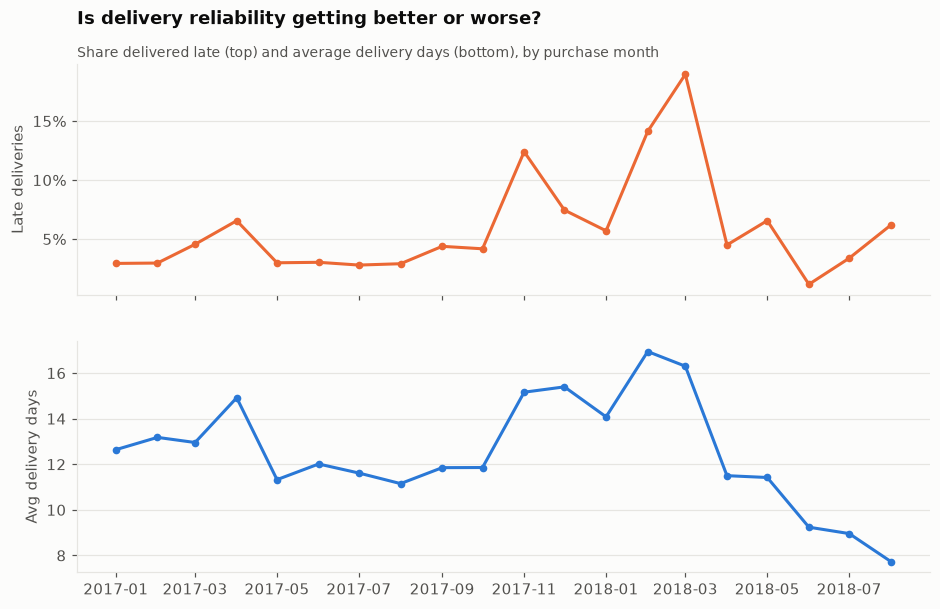

In [21]:
win_valid = valid[valid["in_analysis_window"]]
monthly_delivery = (win_valid.groupby("purchase_year_month")
                    .agg(late_pct=("is_late", lambda s: s.astype(float).mean() * 100),
                         avg_days=("delivery_days", "mean")))
monthly_delivery.index = pd.PeriodIndex(monthly_delivery.index, freq="M").to_timestamp()
print("worst months (late %):", {d.strftime('%Y-%m'): round(v, 2)
      for d, v in monthly_delivery["late_pct"].nlargest(3).items()})
print("best months (late %):", {d.strftime('%Y-%m'): round(v, 2)
      for d, v in monthly_delivery["late_pct"].nsmallest(3).items()})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(monthly_delivery.index, monthly_delivery["late_pct"], color=COLORS["secondary"], marker="o", markersize=4)
ax1.yaxis.set_major_formatter(PCT_FORMATTER)
ax1.set_ylabel("Late deliveries")
ax1.set_title("Is delivery reliability getting better or worse?")
add_subtitle(ax1, "Share delivered late (top) and average delivery days (bottom), by purchase month")
ax2.plot(monthly_delivery.index, monthly_delivery["avg_days"], color=COLORS["primary"], marker="o", markersize=4)
ax2.set_ylabel("Avg delivery days")
save_chart(fig, "09_monthly_delivery_performance"); plt.show()

**Finding.** Late deliveries **spike after demand peaks**: 12.4% in Nov 2017 (Black Friday), then 14.1% in Feb 2018 and **19.0% in Mar 2018**, the worst month, when average delivery time also peaked. Performance then improved sharply, to 1.2% late in Jun 2018, while average delivery time fell to about 8 days by Aug 2018. Logistics capacity did not keep up with growth until mid-2018.

### 9.2 How do customers pay, and how many orders are lost?

payment method, % of orders: {'debit_card': 1.54, 'voucher': 3.89, 'boleto': 19.9, 'credit_card': 76.94}
order status %: {'approved': 0.0, 'created': 0.01, 'processing': 0.3, 'invoiced': 0.32, 'unavailable': 0.61, 'canceled': 0.63, 'shipped': 1.11, 'delivered': 97.02}


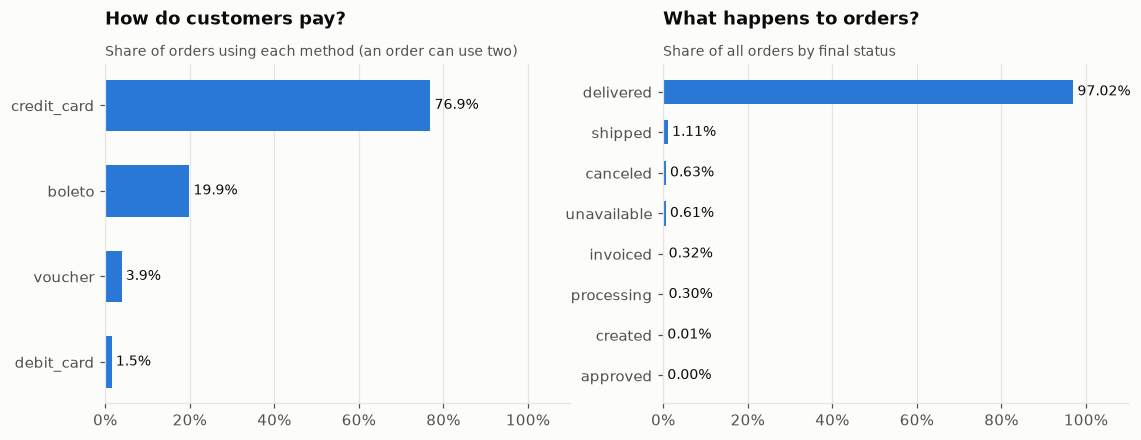

In [22]:
pay = t["payments"].groupby("payment_type")["order_id"].nunique().sort_values()
pay_pct = pay / t["payments"]["order_id"].nunique() * 100
status = orders["order_status"].value_counts(normalize=True).mul(100).sort_values()
print("payment method, % of orders:", pay_pct.round(2).to_dict())
print("order status %:", status.round(2).to_dict())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.barh(pay_pct.index, pay_pct.values, color=COLORS["primary"], height=0.6)
for y, v in enumerate(pay_pct.values):
    ax1.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9)
ax1.set_title("How do customers pay?")
add_subtitle(ax1, "Share of orders using each method (an order can use two)")
ax2.barh(status.index, status.values, color=COLORS["primary"], height=0.6)
for y, v in enumerate(status.values):
    ax2.text(v + 1, y, f"{v:.2f}%", va="center", fontsize=9)
ax2.set_title("What happens to orders?")
add_subtitle(ax2, "Share of all orders by final status")
for ax in (ax1, ax2):
    ax.xaxis.set_major_formatter(PCT_FORMATTER); ax.set_xlim(0, 110)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
save_chart(fig, "09_payments_and_status"); plt.show()

**Finding.** **Credit card is used on 76.9% of orders** and boleto (bank slip) on 19.9%. Vouchers (3.9%) and debit (1.5%) are minor. 97.0% of orders are delivered; only 0.63% are canceled and 0.61% unavailable, so order loss is small compared with the satisfaction impact of late deliveries.

## 10. Consistency check with the SQL analysis
The pandas figures here must match the MySQL query results from Module D.

In [23]:
from src.config import REPORTS_DIR
sql = REPORTS_DIR / "sql_results"
checks = {
    "total revenue": (rev["order_value"].sum(), pd.read_csv(sql / "q01_total_revenue.csv")["total_revenue"][0]),
    "average order value": (rev["order_value"].mean(), pd.read_csv(sql / "q03_average_order_value.csv")["average_order_value"][0]),
    "repeat customer %": ((per_customer["orders"] >= 2).mean() * 100,
                          pd.read_csv(sql / "q09_repeat_customer_rate.csv")["repeat_customer_pct"][0]),
    "late delivery %": (valid["is_late"].astype(float).mean() * 100,
                        pd.read_csv(sql / "q15_late_delivery_rate.csv")["late_delivery_pct"][0]),
}
check_df = pd.DataFrame(checks, index=["pandas", "sql"]).T
check_df["match"] = (check_df["pandas"] - check_df["sql"]).abs() < 0.01
display(check_df)
assert check_df["match"].all(), "pandas and SQL disagree"

,pandas,sql,match
total revenue,"15,735,527.03","15,735,527.03",True
average order value,160.24,160.24,True
repeat customer %,3.04,3.04,True
late delivery %,6.77,6.77,True


## 11. Summary of findings
| Area | Finding (calculated above) | Implication |
|---|---|---|
| Growth | Jan-Aug 2018 revenue +140.4% vs 2017; Black Friday peak R$1.17M; 2018 flat at about R$1.0-1.16M/month | Growth has plateaued and needs new levers |
| Retention | 97.0% of customers buy once; 31% of repeat 'second orders' are same-day | Retention is the largest opportunity |
| Delivery and reviews | Review score falls from 4.31 (early) to 1.70 (8+ days late) | On-time delivery directly protects satisfaction |
| Logistics capacity | Late rate peaked at 19.0% (Mar 2018) after the demand peaks | Plan capacity ahead of peak events |
| Regions | SP = 37.4% of revenue; AL/MA/SE late 15-21%; North 26-29 days | Fix delivery promises/partners region by region |
| Sellers | Top 10% of sellers = 67.5% of revenue | Protect key sellers; grow the long tail |
| Categories | Top 10 categories = 62.4%; revenue vs rating r = 0.00 | Review low-rated categories (office_furniture, audio) |
| Payments | 76.9% of orders use credit card; installments raise basket size | Keep installment options visible |

The next steps (RFM segmentation and the business insights report) build on these results.